# FALCON H1: source data (DANDI 000954)

Open-loop 7-DoF reach and grasp from one human participant with two 96-channel Utah arrays in hand-knob motor cortex, released for the FALCON benchmark (Karpowicz et al. 2024). A virtual arm performs each movement while the participant attempts it with their right hand. The files hold threshold-crossing spike times on 176 channels, the arm's 7-DoF position and velocity on a 20 ms grid, a trial number per sample, FALCON's evaluation mask, and one epochs row per task phase.

This notebook reads the downloaded files through `s.path`, shows how the 40 files relate, and looks at each stream next to the task phases. The [README](README.md) describes the conventions the Study builds on them.

## Setup

The setup cell reads the data root from the repo `.env`, builds the Study and downloads the dandiset (about 102 MB) on the first run. `read_recording` reads every array of one file, and `sample_range` returns the kinematic samples inside a time span.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import neuralshed
from neuralshed.datasets import nwb
from neuralshed.datasets.utils import dataset_dir
from neuralshed.datasets.karpowicz_2024_h1 import utils
from neuralshed.datasets.karpowicz_2024_h1.study import Karpowicz2024FalconH1

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)

# categorical colors, in fixed order
COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]

# Path to your .env (see .env.example). Delete this if the variables are already exported.
ENV_FILE = Path("../../../../.env")

# Arguments override the file, e.g. data_root="/path/to/data". Keep tokens in .env.
neuralshed.configure(
    env_file=ENV_FILE,
    data_root=None,
)

s = Karpowicz2024FalconH1(path=dataset_dir("karpowicz_2024_h1") / "data")
s.download()


def read_recording(path):
    """Every array of one file, from s.path when downloaded, else streamed."""
    source = nwb.resolve_source(
        path,
        utils.DANDISET_ID,
        utils.VERSION,
        root=s.path,
    )
    with nwb.open_nwb(source) as nwbfile:
        epochs = utils.get_epochs(nwbfile)
        return dict(
            position=utils.get_kinematics(nwbfile),
            velocity=utils.get_kinematics(nwbfile, velocity=True),
            trial_num=utils.get_trial_num(nwbfile),
            eval_mask=utils.get_eval_mask(nwbfile),
            spike_times=utils.get_spike_times(nwbfile),
            epochs=pd.DataFrame(
                dict(
                    tag=[str(tags[0]) for tags in epochs.tags],
                    start=epochs.start_time.to_numpy(),
                    stop=epochs.stop_time.to_numpy(),
                )
            ),
        )


def sample_range(start, stop):
    """First and one-past-last index of the kinematic samples in [start, stop)."""
    first = int(np.ceil(start / utils.BIN_SIZE_S - 1e-6))
    last = int(np.ceil(stop / utils.BIN_SIZE_S - 1e-6))
    return first, last


def shade_cues(ax, epochs):
    """Grey spans over the cue phases."""
    for row in epochs.itertuples():
        if row.tag.startswith("Presentation"):
            ax.axvspan(row.start, row.stop, color="0.88", linewidth=0)

neuralshed: NEURALSHED_DATA_ROOT is not set. Export it, or call neuralshed.configure(env_file=...) or neuralshed.configure(data_root=...).


2026-11-12 18:56:05 - INFO - neuralset.events.study:473 - Success: Study downloaded to /Volumes/seagate_0/tether/datasets/karpowicz_2024_h1/data/Karpowicz2024FalconH1.


neuralshed data root: /Volumes/seagate_0/tether/datasets (from /Users/luiztauffer/Github/tether_scratch/.env)


2026-11-12 18:56:06 - INFO - neuralset.events.study:88 - Permissions set for /Volumes/seagate_0/tether/datasets/karpowicz_2024_h1/data/Karpowicz2024FalconH1 (skipped 0 non-owned items).


## Files, recordings and FALCON splits

The dandiset has 40 files in three FALCON splits, named in each file's folder.

In [2]:
paths = nwb.dandi_nwb_paths(
    utils.DANDISET_ID,
    utils.VERSION,
    root=s.path,
)
print(len(paths), "files under", s.path)

pd.Series([utils.split_of(p) for p in paths]).value_counts()

40 files under /Volumes/seagate_0/tether/datasets/karpowicz_2024_h1/data/Karpowicz2024FalconH1


held-out-calib     14
held-in-calib      13
held-in-minival    13
Name: count, dtype: int64

`utils.recordings` keeps the 27 held-in-calib and held-out-calib files, one per recording, and numbers the recordings of each day by start time (`block`). FALCON's code names the same recordings `S<day>_set_<block>`, with the 13 days numbered in date order. The timestamps are anonymized to 1925 and keep the spacing between days. The 6 held-in days hold whole recordings without their last 20%, the 7 held-out days only the first 20% of each recording, and FALCON keeps the rest for its hidden evaluation.

In [3]:
recordings = pd.DataFrame(utils.recordings(paths))

days = sorted(recordings.day.unique())
recordings["falcon_id"] = [
    f"S{days.index(day)}_set_{block}"
    for day, block in zip(recordings.day, recordings.block)
]

recordings[["session", "split", "falcon_id", "path"]]

,session,split,falcon_id,path
0,19250101_block1,held-in-calib,S0_set_1,000954/sub-HumanPitt-held-in-calib/sub-HumanPitt-held-in-calib_ses-19250101T111740.nwb
1,19250101_block2,held-in-calib,S0_set_2,000954/sub-HumanPitt-held-in-calib/sub-HumanPitt-held-in-calib_ses-19250101T112404.nwb
2,19250108_block1,held-in-calib,S1_set_1,000954/sub-HumanPitt-held-in-calib/sub-HumanPitt-held-in-calib_ses-19250108T110520.nwb
3,19250108_block2,held-in-calib,S1_set_2,000954/sub-HumanPitt-held-in-calib/sub-HumanPitt-held-in-calib_ses-19250108T111022.nwb
4,19250108_block3,held-in-calib,S1_set_3,000954/sub-HumanPitt-held-in-calib/sub-HumanPitt-held-in-calib_ses-19250108T111455.nwb
5,19250113_block1,held-in-calib,S2_set_1,000954/sub-HumanPitt-held-in-calib/sub-HumanPitt-held-in-calib_ses-19250113T120811.nwb
6,19250113_block2,held-in-calib,S2_set_2,000954/sub-HumanPitt-held-in-calib/sub-HumanPitt-held-in-calib_ses-19250113T121303.nwb
7,19250115_block1,held-in-calib,S3_set_1,000954/sub-HumanPitt-held-in-calib/sub-HumanPitt-held-in-calib_ses-19250115T110633.nwb
8,19250115_block2,held-in-calib,S3_set_2,000954/sub-HumanPitt-held-in-calib/sub-HumanPitt-held-in-calib_ses-19250115T111328.nwb
9,19250119_block1,held-in-calib,S4_set_1,000954/sub-HumanPitt-held-in-calib/sub-HumanPitt-held-in-calib_ses-19250119T113543.nwb


FALCON provides the held-in-minival files to check that a submission runs. Each one repeats the first 1,503-1,831 samples of the held-in-calib file with the same timestamp, so the Study leaves them out. The cell reads all 40 files and compares each minival file with its calib file over the minival's length: the four per-sample series, the spike counts binned on the kinematic grid, and the epochs. Everything matches except the last epoch row, which the minival file cuts at its end and tags `Intertrial`, where the calib file tags the same row `Release`. The `Intertrial` row that ends every recording is such a cut `Release`, and the Study emits it as one (see "The last Release" in the README).

In [4]:
data = {path: read_recording(path) for path in paths}

rows = []
for path in paths:
    if utils.split_of(path) != utils.MINIVAL_SPLIT:
        continue
    copy = data[path]
    calib = data[path.replace(utils.MINIVAL_SPLIT, "held-in-calib")]
    n = len(copy["position"])
    copy_epochs = copy["epochs"]
    calib_epochs = calib["epochs"].iloc[: len(copy_epochs)]
    rows.append(
        dict(
            file=Path(path).name,
            samples=n,
            calib_samples=len(calib["position"]),
            series_equal=all(
                np.array_equal(copy[key], calib[key][:n])
                for key in ("position", "velocity", "trial_num", "eval_mask")
            ),
            spike_counts_equal=np.array_equal(
                utils.bin_spike_times(copy["spike_times"], n),
                utils.bin_spike_times(calib["spike_times"], n),
            ),
            epochs_equal_but_last=copy_epochs.iloc[:-1].equals(calib_epochs.iloc[:-1]),
            last_start_equal=copy_epochs.start.iloc[-1] == calib_epochs.start.iloc[-1],
            last_tag=copy_epochs.tag.iloc[-1],
            calib_tag=calib_epochs.tag.iloc[-1],
        )
    )

pd.DataFrame(rows)

,file,samples,calib_samples,series_equal,spike_counts_equal,epochs_equal_but_last,last_start_equal,last_tag,calib_tag
0,sub-HumanPitt-held-in-minival_ses-19250101T111740.nwb,1503,10819,True,True,True,True,Intertrial,Release
1,sub-HumanPitt-held-in-minival_ses-19250101T112404.nwb,1714,6456,True,True,True,True,Intertrial,Release
2,sub-HumanPitt-held-in-minival_ses-19250108T110520.nwb,1691,12233,True,True,True,True,Intertrial,Release
3,sub-HumanPitt-held-in-minival_ses-19250108T111022.nwb,1831,6786,True,True,True,True,Intertrial,Release
4,sub-HumanPitt-held-in-minival_ses-19250108T111455.nwb,1761,6505,True,True,True,True,Intertrial,Release
5,sub-HumanPitt-held-in-minival_ses-19250113T120811.nwb,1530,11646,True,True,True,True,Intertrial,Release
6,sub-HumanPitt-held-in-minival_ses-19250113T121303.nwb,1536,11732,True,True,True,True,Intertrial,Release
7,sub-HumanPitt-held-in-minival_ses-19250115T110633.nwb,1547,10071,True,True,True,True,Intertrial,Release
8,sub-HumanPitt-held-in-minival_ses-19250115T111328.nwb,1530,12267,True,True,True,True,Intertrial,Release
9,sub-HumanPitt-held-in-minival_ses-19250119T113543.nwb,1583,11951,True,True,True,True,Intertrial,Release


## One recording

The next sections use `19250126_block1`, the first held-out-calib recording (FALCON's `S6_set_1`). The cell opens its local file and lists what it holds.

In [5]:
SAMPLE = "19250126_block1"

sample_path = recordings.set_index("session").loc[SAMPLE, "path"]
sample = data[sample_path]

source = nwb.resolve_source(
    sample_path,
    utils.DANDISET_ID,
    utils.VERSION,
    root=s.path,
)
print(source)

with nwb.open_nwb(source) as nwbfile:
    print("session_description:", nwbfile.session_description)
    print("lab:", nwbfile.lab, "|", nwbfile.institution)
    print(
        "subject:",
        nwbfile.subject.subject_id,
        "| sex:",
        nwbfile.subject.sex,
        "| age:",
        nwbfile.subject.age,
    )
    print("units:", len(nwbfile.units.id), "rows, columns", nwbfile.units.colnames)
    print("electrodes table:", nwbfile.electrodes)
    print("intervals:", list(nwbfile.intervals))
    acquisition = pd.DataFrame(
        [
            dict(
                name=name,
                shape=series.data.shape,
                dtype=series.data.dtype,
                unit=series.unit,
                rate_field=series.rate,
                description=series.description,
            )
            for name, series in nwbfile.acquisition.items()
        ]
    )

acquisition

/Volumes/seagate_0/tether/datasets/karpowicz_2024_h1/data/Karpowicz2024FalconH1/000954/sub-HumanPitt-held-out-calib/sub-HumanPitt-held-out-calib_ses-19250126T113454.nwb
session_description: FALCON H1. Open loop 7DoF calibration.
lab: Rehab Neural Engineering Labs | University of Pittsburgh
subject: HumanPitt-held_out-calib | sex: U | age: P22Y/P70Y
units: 176 rows, columns ('spike_times',)
electrodes table: None
intervals: ['epochs']


,name,shape,dtype,unit,rate_field,description
0,OpenLoopKinematics,"(2376, 7)",float64,arbitrary,0.02,"tx,ty,tz,rx,g1,g2,g3"
1,OpenLoopKinematicsVelocity,"(2376, 7)",float32,arbitrary,0.02,"tx,ty,tz,rx,g1,g2,g3"
2,TrialNum,"(2376,)",float64,arbitrary,0.02,Trial number
3,eval_mask,"(2376,)",bool,bool,0.02,"Timesteps to ignore covariates (for training, eval). Neural data is not affected."


All four series store `rate = 0.02`, which is the bin period in seconds: sample `k` sits at `k * 0.02` s, 50 samples per second. The units table has one row per channel and no `electrodes` column, and the file has no electrodes table, so the electrode behind each channel is not released. The DANDI description also lists a `Blacklist` series, which none of the files has.

The same file can be streamed from DANDI without downloading it. Without `root`, `nwb.resolve_source` returns the asset's streaming URL, and `nwb.open_nwb` reads only the bytes a call touches.

In [6]:
url = nwb.resolve_source(
    sample_path,
    utils.DANDISET_ID,
    utils.VERSION,
)
print(url)

with nwb.open_nwb(url) as nwbfile:
    streamed = utils.get_kinematics(nwbfile)

print("same kinematics as the local file:", np.array_equal(streamed, sample["position"]))

https://api.dandiarchive.org/api/dandisets/000954/versions/draft/assets/dbec5a3f-46a3-4c8d-bb88-6e8546b0c729/download/


same kinematics as the local file: True


## Spike times

Each units row holds the spike times of one channel: unsorted threshold crossings at -4.5 x RMS, per the FALCON H1 demo. The table gives, per recording, the earliest and latest spike, the spikes before 0 s, the time of the last kinematic sample, and the channels without any spike. Spike times run from -0.02 s at the earliest to the last kinematic sample, and channel 66 has no spike in any recording.

In [7]:
rows = []
for rec in recordings.itertuples():
    spike_times = data[rec.path]["spike_times"]
    times = np.concatenate(spike_times)
    n = len(data[rec.path]["position"])
    rows.append(
        dict(
            session=rec.session,
            first_spike_s=times.min(),
            spikes_before_0=int((times < 0).sum()),
            last_spike_s=times.max(),
            last_sample_s=(n - 1) * utils.BIN_SIZE_S,
            silent_channels=[ch for ch, t in enumerate(spike_times) if t.size == 0],
        )
    )

spike_extent = pd.DataFrame(rows).set_index("session")
display(spike_extent.round(4))

print("recordings with spikes before 0 s:", int((spike_extent.spikes_before_0 > 0).sum()))
print("earliest spike (s):", round(spike_extent.first_spike_s.min(), 4))
print("silent channels in every recording:", set.intersection(*map(set, spike_extent.silent_channels)))

,first_spike_s,spikes_before_0,last_spike_s,last_sample_s,silent_channels
session,,,,,
19250101_block1,-0.0200,46,216.3595,216.36,[66]
19250101_block2,-0.0015,8,129.0992,129.10,[66]
19250108_block1,-0.0029,6,244.6397,244.64,[66]
19250108_block2,-0.0014,2,135.6999,135.70,[66]
19250108_block3,-0.0016,2,130.0793,130.08,[66]
19250113_block1,-0.0023,10,232.8991,232.90,[66]
19250113_block2,0.0079,0,234.6200,234.62,[66]
19250115_block1,-0.0195,81,201.3997,201.40,[66]
19250115_block2,0.0072,0,245.3200,245.32,[66]


recordings with spikes before 0 s: 15
earliest spike (s): -0.02
silent channels in every recording: {66}


Kinematic sample `k` goes with the spikes of the 20 ms that end at it, as FALCON's `bin_units` bins them, so the first bin starts at -0.02 s. `utils.bin_edges` gives these edges, and binned this way every spike of every recording falls into a bin.

In [8]:
print("first bin edges (s):", utils.bin_edges(4))

n_spikes = 0
n_binned = 0
for rec in recordings.itertuples():
    spike_times = data[rec.path]["spike_times"]
    n = len(data[rec.path]["position"])
    n_spikes += sum(t.size for t in spike_times)
    n_binned += int(utils.bin_spike_times(spike_times, n).sum())

print("spikes:", n_spikes, "| in a bin:", n_binned)

first bin edges (s): [-0.02  0.    0.02  0.04  0.06]


spikes: 8385405 | in a bin: 8385405


The binned counts of the sample recording, with the cue phases marked above.

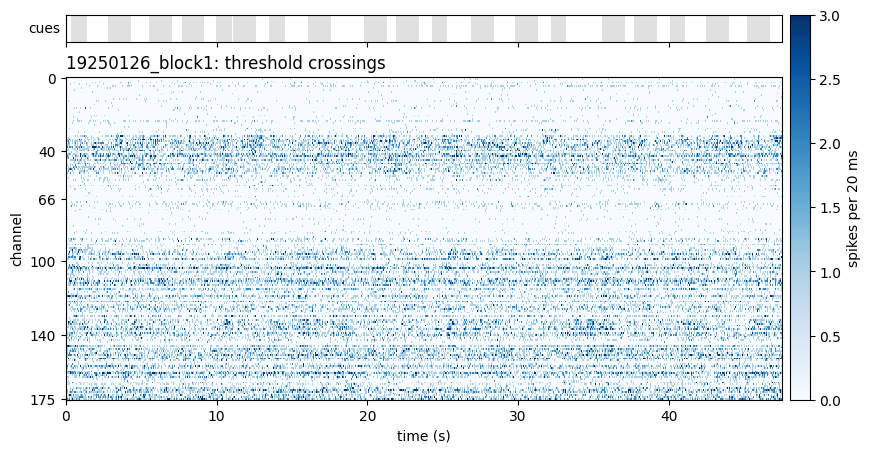

In [9]:
counts = utils.bin_spike_times(sample["spike_times"], len(sample["position"]))
duration = len(sample["position"]) * utils.BIN_SIZE_S

fig, (ax_cue, ax) = plt.subplots(
    2,
    1,
    figsize=(11, 5),
    sharex=True,
    gridspec_kw=dict(height_ratios=[1, 12]),
)
shade_cues(ax_cue, sample["epochs"])
ax_cue.set_yticks([])
ax_cue.set_ylabel("cues", rotation=0, ha="right", va="center")

image = ax.imshow(
    counts,
    aspect="auto",
    cmap="Blues",
    interpolation="none",
    extent=(-utils.BIN_SIZE_S, duration - utils.BIN_SIZE_S, counts.shape[0] - 0.5, -0.5),
    vmax=np.percentile(counts, 99.5),
)
ax.set_xlabel("time (s)")
ax.set_ylabel("channel")
ax.set_yticks([0, 40, 66, 100, 140, 175])
fig.colorbar(image, ax=[ax_cue, ax], label="spikes per 20 ms", pad=0.01)
ax.set_title(f"{SAMPLE}: threshold crossings", loc="left")
plt.show()

## Kinematics

`OpenLoopKinematics` holds the arm's position, one column per DoF in the order of its description: 3 translation (`tx, ty, tz`), roll (`rx`) and 3 grasp dimensions (`g1, g2, g3`, pinch, scoop and thumb abduction per FALCON). Both kinematics series declare `unit="arbitrary"`. The table gives each DoF's range over the 27 recordings.

In [10]:
position = np.concatenate([data[p]["position"] for p in recordings.path])

pd.DataFrame(
    dict(
        min=position.min(axis=0),
        max=position.max(axis=0),
    ),
    index=list(utils.DOF_LABELS),
).round(3)

,min,max
tx,0.342,0.544
ty,-0.294,0.159
tz,-0.264,0.262
rx,-0.967,0.849
g1,0.000,0.980
g2,0.000,1.000
g3,0.000,1.000


The sample recording holds three trials. Grey spans mark the cue phases. In the first 0.3 s of a cue the arm finishes the previous movement, then translation and roll hold still and grasp jitters, which the FALCON demo puts down to the simulator's physics.

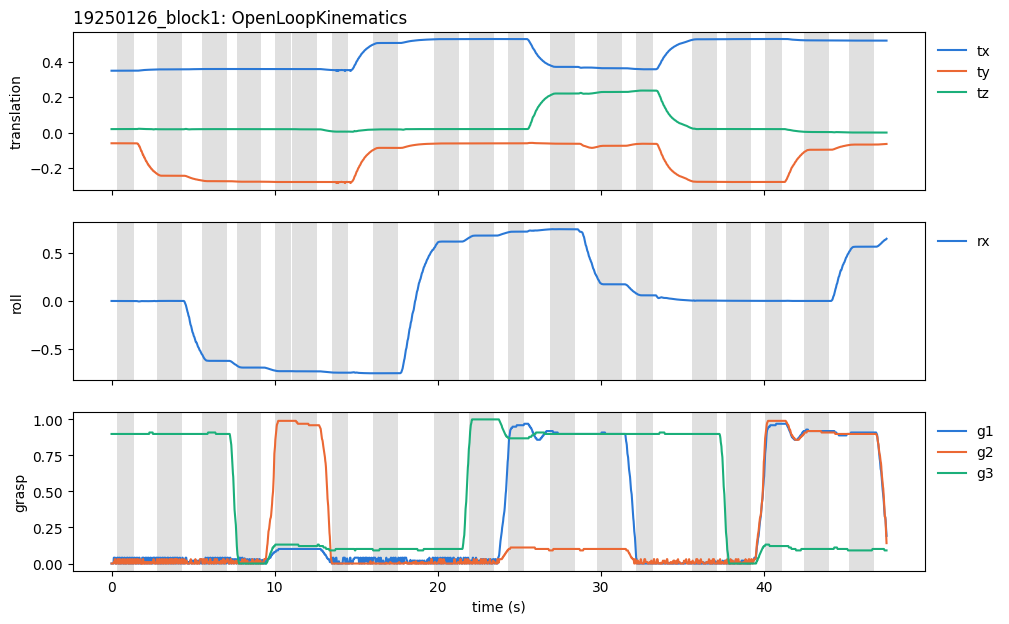

In [11]:
time = np.arange(len(sample["position"])) * utils.BIN_SIZE_S
groups = [
    ("translation", [0, 1, 2]),
    ("roll", [3]),
    ("grasp", [4, 5, 6]),
]

fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
for ax, (name, cols) in zip(axes, groups):
    shade_cues(ax, sample["epochs"])
    for color, col in zip(COLORS, cols):
        ax.plot(
            time,
            sample["position"][:, col],
            color=color,
            linewidth=1.5,
            label=utils.DOF_LABELS[col],
        )
    ax.set_ylabel(name)
    ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), frameon=False)

axes[-1].set_xlabel("time (s)")
axes[0].set_title(f"{SAMPLE}: OpenLoopKinematics", loc="left")
plt.show()

`OpenLoopKinematicsVelocity` is a smoothed derivative of position per sample. The table compares it, per DoF and over the 27 recordings, with `np.gradient` of position, which is also a difference per sample. They correlate at 0.84-0.93 and the velocity's spread is 0.77-0.90 of the gradient's, the smoothing taking off the jitter, where a derivative per second would be 50 times larger. The plot shows `ty`, the reach of the sample's first trial.

,correlation,std_ratio
tx,0.842,0.810
ty,0.898,0.866
tz,0.836,0.803
rx,0.930,0.903
g1,0.841,0.784
g2,0.848,0.774
g3,0.934,0.841


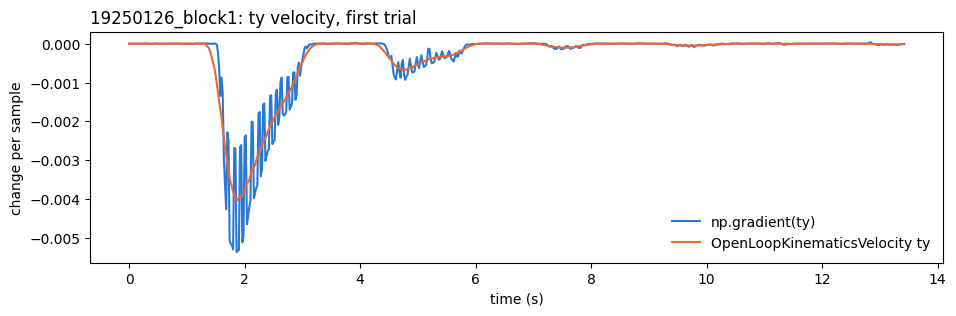

In [12]:
gradient = np.concatenate(
    [np.gradient(data[p]["position"], axis=0) for p in recordings.path]
)
velocity = np.concatenate([data[p]["velocity"] for p in recordings.path])

display(
    pd.DataFrame(
        dict(
            correlation=[
                np.corrcoef(gradient[:, d], velocity[:, d])[0, 1]
                for d in range(len(utils.DOF_LABELS))
            ],
            std_ratio=velocity.std(axis=0) / gradient.std(axis=0),
        ),
        index=list(utils.DOF_LABELS),
    ).round(3)
)

first_trial = sample["trial_num"] == sample["trial_num"].min()

fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(
    time[first_trial],
    np.gradient(sample["position"][:, 1])[first_trial],
    color=COLORS[0],
    linewidth=1.5,
    label="np.gradient(ty)",
)
ax.plot(
    time[first_trial],
    sample["velocity"][first_trial, 1],
    color=COLORS[1],
    linewidth=1.5,
    label="OpenLoopKinematicsVelocity ty",
)
ax.set_xlabel("time (s)")
ax.set_ylabel("change per sample")
ax.legend(loc="lower right", frameon=False)
ax.set_title(f"{SAMPLE}: ty velocity, first trial", loc="left")
plt.show()

## Task phases

Each epochs row is one task phase with a single tag. The first trial of the sample opens with the rest before it and has no `Presentation6`: its `Carry` and `Orient2` last two samples and one, with nothing to move (see "Phases without movement" in the README).

In [13]:
sample_trial_ids = utils.phase_trial_ids(
    sample["trial_num"],
    sample["epochs"].start,
    sample["epochs"].stop,
)

sample["epochs"][sample_trial_ids == sample_trial_ids.min()].round(2)

,tag,start,stop
0,Intertrial,0.00,0.32
1,Presentation,0.32,1.40
2,Reach,1.40,2.76
3,Presentation2,2.76,4.29
4,Orient,4.29,5.39
5,SnapTo,5.39,5.53
6,Presentation3,5.53,7.07
7,Shape,7.07,7.67
8,Presentation4,7.67,9.19
9,Grasp,9.19,9.99


The cell collects the 3,052 phase rows of the 27 recordings with their trial (`utils.phase_trial_ids`, the `TrialNum` value over most of the row) and, per DoF group, how far the arm moves during the row. The first and last `Intertrial` rows of a recording are labeled apart. The table gives, per tag, the rows, the median duration and the median movement of translation, roll and grasp (Euclidean distance within the group). `Reach` and `Carry` move translation, `Orient` and `Orient2` roll, `Shape`, `Grasp` and `Release` grasp, and `SnapTo` a little of translation and roll. The last `Intertrial` opens the hand like `Release`. The cues move little, mostly the grasp that settles after `Shape` and `Grasp` in `Presentation4` and `Presentation5`.

In [14]:
rows = []
for rec in recordings.itertuples():
    rec_data = data[rec.path]
    epochs = rec_data["epochs"]
    trial_ids = utils.phase_trial_ids(rec_data["trial_num"], epochs.start, epochs.stop)
    for i, (row, trial_id) in enumerate(zip(epochs.itertuples(), trial_ids)):
        first, last = sample_range(row.start, row.stop)
        before = rec_data["position"][max(first - 1, 0)]
        after = rec_data["position"][last - 1]
        tag = row.tag
        if tag == "Intertrial":
            tag = "Intertrial (first row)" if i == 0 else "Intertrial (last row)"
        rows.append(
            dict(
                session=rec.session,
                tag=tag,
                start=row.start,
                stop=row.stop,
                duration=row.stop - row.start,
                first_sample=first,
                last_sample=last,
                trial_id=trial_id,
                translation=np.linalg.norm(after[:3] - before[:3]),
                roll=abs(after[3] - before[3]),
                grasp=np.linalg.norm(after[4:] - before[4:]),
            )
        )

phases = pd.DataFrame(rows)
print(len(phases), "phase rows")

# task order, the Intertrial rows at either end
PHASE_ORDER = [
    "Intertrial (first row)",
    "Presentation",
    "Reach",
    "Presentation2",
    "Orient",
    "SnapTo",
    "Presentation3",
    "Shape",
    "Presentation4",
    "Grasp",
    "Presentation5",
    "Carry",
    "Presentation6",
    "Orient2",
    "Presentation7",
    "Release",
    "Intertrial (last row)",
]

(
    phases.groupby("tag")
    .agg(
        rows=("tag", "size"),
        duration_s=("duration", "median"),
        translation=("translation", "median"),
        roll=("roll", "median"),
        grasp=("grasp", "median"),
    )
    .reindex(PHASE_ORDER)
    .round(3)
)

3052 phase rows


,rows,duration_s,translation,roll,grasp
tag,,,,,
Intertrial (first row),25,0.08,0.000,0.000,0.000
Presentation,212,1.04,0.001,0.019,0.052
Reach,212,1.59,0.252,0.047,0.000
Presentation2,130,1.52,0.014,0.002,0.010
Orient,211,1.12,0.022,0.502,0.000
SnapTo,212,0.39,0.007,0.042,0.005
Presentation3,212,1.54,0.004,0.052,0.010
Shape,212,0.62,0.001,0.027,0.717
Presentation4,212,1.52,0.001,0.015,0.182


Phase rows are not trials. Per recording, the phase rows, the trials from `phase_trial_ids` and the distinct `TrialNum` values: 212 trials in all, 8 to 15 per held-in recording and 3 per held-out recording.

In [15]:
per_recording = phases.groupby("session").agg(
    phase_rows=("tag", "size"),
    trials=("trial_id", "nunique"),
)
per_recording["trial_num_values"] = [
    np.unique(data[path]["trial_num"]).size
    for path in recordings.set_index("session").loc[per_recording.index, "path"]
]

display(per_recording.T)
print("total:", per_recording.sum().to_dict())

session,19250101_block1,19250101_block2,19250108_block1,19250108_block2,19250108_block3,19250113_block1,19250113_block2,19250115_block1,19250115_block2,19250119_block1,...,19250129_block1,19250129_block2,19250202_block1,19250202_block2,19250203_block1,19250203_block2,19250206_block1,19250206_block2,19250209_block1,19250209_block2
phase_rows,187,115,218,117,116,214,213,183,215,214,...,44,44,44,44,44,43,44,44,46,45
trials,13,8,15,8,8,15,15,13,15,15,...,3,3,3,3,3,3,3,3,3,3
trial_num_values,13,8,15,8,8,15,15,13,15,15,...,3,3,3,3,3,3,3,3,3,3


total: {'phase_rows': 3052, 'trials': 212, 'trial_num_values': 212}


`TrialNum` steps to the next trial a few samples before a `Release` row ends, so these rows span two trials and `phase_trial_ids` takes the one covering most of the row. Over the 185 `Release` rows that hold a step, the count of samples from the step to the row end, 2-4 in 180 of them:

In [16]:
steps = []
for row in phases[phases.tag == "Release"].itertuples():
    trial_num = data[recordings.set_index("session").loc[row.session, "path"]]["trial_num"]
    values = trial_num[row.first_sample : row.last_sample]
    changes = np.flatnonzero(np.diff(values))
    if changes.size:
        steps.append(len(values) - (changes[0] + 1))

pd.Series(steps, name="samples after the step").value_counts().sort_index()

samples after the step
2      29
3     107
4      44
5       2
6       1
8       1
11      1
Name: count, dtype: int64

## FALCON evaluation mask

`eval_mask` marks the samples FALCON trains on and scores. FALCON's loader reads True as scored, while the series description states the opposite. 96.2-98.3% of each recording's samples are scored:

In [17]:
print("description:", repr(acquisition.set_index("name").loc["eval_mask", "description"]))

scored = pd.Series(
    {
        rec.session: data[rec.path]["eval_mask"].mean()
        for rec in recordings.itertuples()
    },
    name="scored",
)
scored.describe()[["min", "max"]].round(3)

description: 'Timesteps to ignore covariates (for training, eval). Neural data is not affected.'


min    0.962
max    0.983
Name: scored, dtype: float64

Per tag, the samples inside the rows and the share of them that are scored. FALCON leaves out `SnapTo` (30 of its 4,193 samples are scored, each the last sample of a row), the rest before the first trial (3 of 201) and 31 `Orient` samples, and scores everything else, the last `Intertrial` rows included. The Study emits the mask as a `BinaryMask` row.

In [18]:
rows = []
for row in phases.itertuples():
    mask = data[recordings.set_index("session").loc[row.session, "path"]]["eval_mask"]
    inside = mask[row.first_sample : row.last_sample]
    rows.append(dict(tag=row.tag, samples=inside.size, scored=int(inside.sum())))

by_tag = pd.DataFrame(rows).groupby("tag")[["samples", "scored"]].sum()
by_tag["share"] = (by_tag.scored / by_tag.samples).round(3)
by_tag.reindex(PHASE_ORDER)

,samples,scored,share
tag,,,
Intertrial (first row),201,3,0.015
Presentation,10984,10984,1.000
Reach,15734,15734,1.000
Presentation2,9934,9934,1.000
Orient,9755,9724,0.997
SnapTo,4193,30,0.007
Presentation3,16218,16218,1.000
Shape,6522,6522,1.000
Presentation4,16199,16199,1.000
